<a href="https://colab.research.google.com/github/luibus/Ejemplo-corto-PINNs/blob/main/ejemplo_inicial_pinn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Iniciando entrenamiento...
Época    0 | Pérdida Total: 0.76915 (Física: 0.10036 | Inicio: 0.66879)
Época  200 | Pérdida Total: 0.05309 (Física: 0.04080 | Inicio: 0.01229)
Época  400 | Pérdida Total: 0.00036 (Física: 0.00033 | Inicio: 0.00003)
Época  600 | Pérdida Total: 0.00010 (Física: 0.00010 | Inicio: 0.00000)
Época  800 | Pérdida Total: 0.00006 (Física: 0.00006 | Inicio: 0.00001)
Época 1000 | Pérdida Total: 0.00015 (Física: 0.00011 | Inicio: 0.00005)
Época 1200 | Pérdida Total: 0.00002 (Física: 0.00002 | Inicio: 0.00000)
Época 1400 | Pérdida Total: 0.00002 (Física: 0.00002 | Inicio: 0.00001)
Época 1600 | Pérdida Total: 0.00005 (Física: 0.00003 | Inicio: 0.00002)
Época 1800 | Pérdida Total: 0.00008 (Física: 0.00006 | Inicio: 0.00002)


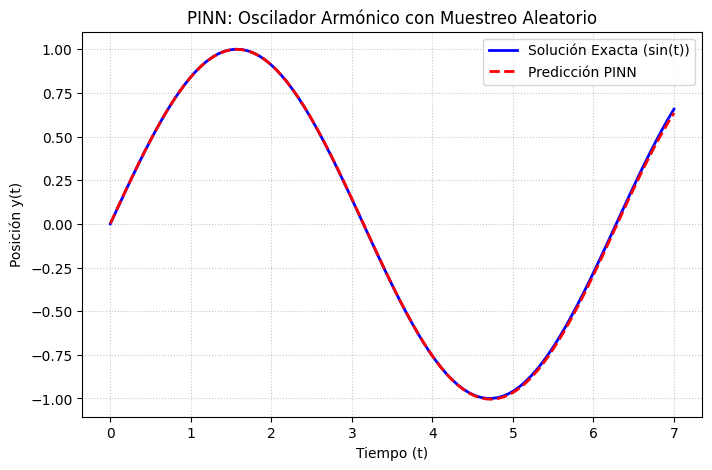

In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# 1. Define the Neural Network
class PINNOscilador(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 20), nn.Tanh(),
            nn.Linear(20, 20), nn.Tanh(),
            nn.Linear(20, 1)
        )
    def forward(self, t):
        return self.net(t)

model = PINNOscilador()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

# Initial Condition Point (The fixed point that we need to make the problem unique) here we need to impose over the values y(t=t0) and y'(t=t0)
t0 = torch.tensor([[0.0]], requires_grad=True)

# 2. Random Sampling Training
print("Iniciando entrenamiento...")
for epoch in range(2000):
    optimizer.zero_grad()

    # Random Sampling of 100 points in between 0 and 2*pi on each epoch
    t = (torch.rand(100, 1) * 6.28).requires_grad_(True)

    # --- A) PHYSICAL LOSS: y'' + y = 0 ---
    y = model(t)
    dy_dt = torch.autograd.grad(y, t, torch.ones_like(y), create_graph=True)[0]
    d2y_dt2 = torch.autograd.grad(dy_dt, t, torch.ones_like(dy_dt), create_graph=True)[0]
    loss_f = torch.mean((d2y_dt2 + y)**2)

    # --- B) INITIAL CONDITIONS: y(0)=0, y'(0)=1 ---
    y0 = model(t0)
    dy0_dt = torch.autograd.grad(y0, t0, torch.ones_like(y0), create_graph=True)[0]
    loss_ic = (y0 - 0.0)**2 + (dy0_dt - 1.0)**2

    # --- C) OPTIMIZE ---
    loss = loss_f + loss_ic
    loss.backward()
    optimizer.step()

    # Print on Screen during Training
    if epoch % 200 == 0:
        print(f"Época {epoch:4d} | Pérdida Total: {loss.item():.5f} (Física: {loss_f.item():.5f} | Inicio: {loss_ic.item():.5f})")

# 3. Plots (We use linspace just for smooth curve but it can be whatever that there wont be overfitting)
with torch.no_grad():
    t_plot = torch.linspace(0, 7, 100).view(-1, 1)
    y_pred = model(t_plot)
    y_real = torch.sin(t_plot)

    plt.figure(figsize=(8, 5))
    plt.plot(t_plot.numpy(), y_real.numpy(), label="Solución Exacta (sin(t))", color='blue', linewidth=2)
    plt.plot(t_plot.numpy(), y_pred.numpy(), '--', label="Predicción PINN", color='red', linewidth=2)

    plt.xlabel("Tiempo (t)")
    plt.ylabel("Posición y(t)")
    plt.title("PINN: Oscilador Armónico con Muestreo Aleatorio")
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.show()

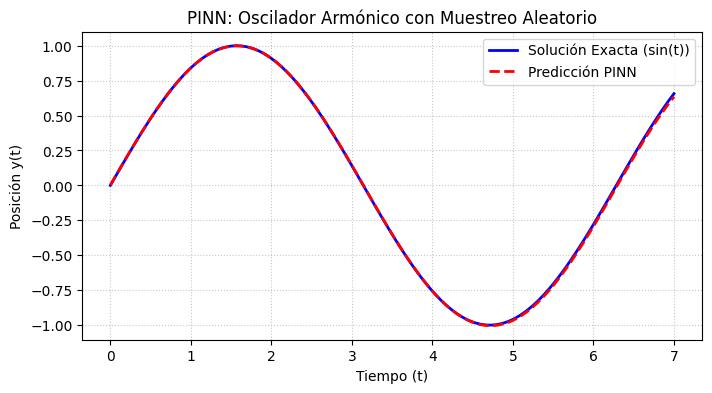

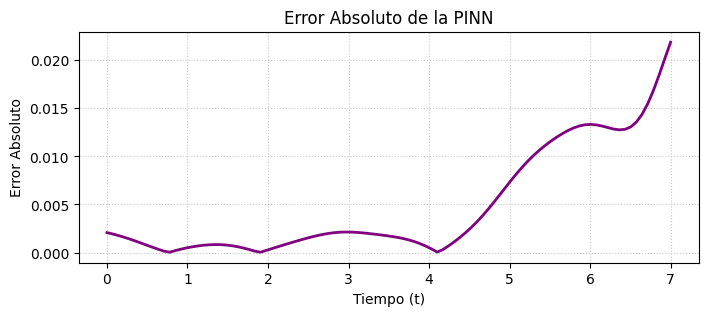

In [ ]:
# 3. Results and error plots
with torch.no_grad():
    t_plot = torch.linspace(0, 7, 100).view(-1, 1)
    y_pred = model(t_plot)
    y_real = torch.sin(t_plot)

    plt.figure(figsize=(8, 4))
    plt.plot(t_plot.numpy(), y_real.numpy(), label="Solución Exacta (sin(t))", color='blue', linewidth=2)
    plt.plot(t_plot.numpy(), y_pred.numpy(), '--', label="Predicción PINN", color='red', linewidth=2)
    plt.xlabel("Tiempo (t)")
    plt.ylabel("Posición y(t)")
    plt.title("PINN: Oscilador Armónico con Muestreo Aleatorio")
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.show()

    plt.figure(figsize=(8, 3))
    plt.plot(t_plot.numpy(), torch.abs(y_real - y_pred).numpy(), color='purple', linewidth=2)
    plt.xlabel("Tiempo (t)")
    plt.ylabel("Error Absoluto")
    plt.title("Error Absoluto de la PINN")
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.show()